# Rediscovering the parameters of a simulation with Celldetective

This notebook generates a synthetic effector–target experiment whose rules are
known exactly, then forgets them and analyses the movie with the Celldetective
API, as it would a real experiment: threshold segmentation, tracking,
measurements, death detection, contact neighborhoods, pairs, contact episodes
and a contact hazard model. At the end, each parameter recovered from the
images is set against the value the simulation used.

**The simulation.** Targets are disks that jiggle in place (channel
`live_nuclei_channel`). Effectors are smaller disks that roam, dock to a target
for a scripted number of frames and leave (channel `effector_fluo_channel`). At
each frame a target spends in contact, it receives a lethal hit with a fixed
probability, and is seen dead after an incompressible delay of a few frames;
it can also die at any frame regardless of contacts (a background death
rate). Dead targets light up in `dead_nuclei_channel`.

The only inputs of the analysis are the experiment folder written to disk and
generic choices (an intensity threshold, a tracking search range). Part I
recovers the parameters of a simple killing: a constant hit probability per
frame of contact, a delay and a background death rate. Part II adds, one at a
time, richer killing mechanisms (cooperation between effectors, contact
maturation, effector exhaustion, resistant targets, the death of neighboring
targets, a variable delay) and devises a way to detect each and measure it.
It needs no model download; part II takes several minutes.

In [1]:
import os
import tempfile
import warnings

os.environ["TQDM_DISABLE"] = "1"  # no progress bars in the notebook's outputs
from scipy.optimize import OptimizeWarning
warnings.simplefilter("ignore", OptimizeWarning)  # death-time fits on clean step signals

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Two populations, two fixed colors: targets blue, effectors orange.
TARGETS, EFFECTORS = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 100, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 10,
})

The figures of the notebook are drawn with the few helpers below: a row of
panels, a dashed marker, estimates with their 95% interval, event rates,
hazard ratios by lag and survival curves.

In [2]:
from celldetective.utils.maths import step_function


def panels(n=1, size=(6, 3.2), **kwargs):
    # A row of n panels of the given size each; a single Axes when n == 1.
    _, axes = plt.subplots(1, n, figsize=(size[0] * n, size[1]), layout="constrained", **kwargs)
    return axes


def mark(ax, x, text=None):
    # A dashed vertical line at a threshold or an estimate, labelled at the top if text is given.
    ax.axvline(x, color=INK, lw=1, ls="--")
    if text:
        ax.text(x, ax.get_ylim()[1], f"  {text}", va="top", fontsize=9)


def wilson(k, n, z=1.96):
    # Wilson 95% interval of k successes out of n trials.
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


def plot_estimates(ax, x, estimate, lower, upper, color=TARGETS, **kwargs):
    # Point estimates with their 95% interval as error bars.
    estimate = np.asarray(estimate, dtype=float)
    yerr = [estimate - np.asarray(lower), np.asarray(upper) - estimate]
    ax.errorbar(x, estimate, yerr=yerr, fmt="o", color=color, ms=7, lw=2, capsize=0, **kwargs)


def plot_rates(ax, counts, color=TARGETS, label="observed (95% CI)"):
    # Event rates of a count table (columns "sum" and "size", one row per x), with Wilson intervals.
    low, high = wilson(counts["sum"].to_numpy(), counts["size"].to_numpy())
    plot_estimates(ax, counts.index, counts["sum"] / counts["size"], low, high, color, label=label)


def plot_hazard_ratios(ax, fits, color=TARGETS):
    # Hazard ratios of contact by lag (one row per lag) with their 95% CI, on a log scale around 1.
    plot_estimates(ax, fits.index, fits["hazard_ratio"], fits["ci_lower"], fits["ci_upper"], color)
    ax.axhline(1, color=MUTED, lw=1)
    ax.set(yscale="log", xticks=list(fits.index), ylabel="hazard ratio of contact")


def plot_survival(ax, km, color=TARGETS, band=False, **kwargs):
    # The survival curve of a fitted Kaplan-Meier estimator, with its 95% band if asked.
    survival = km.survival_function_.iloc[:, 0]
    if band:
        ci = km.confidence_interval_
        ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step="post", color=color, alpha=0.15, lw=0)
    ax.step(survival.index, survival.to_numpy(), where="post", color=color, lw=2, **kwargs)
    ax.set(ylim=(0, 1.02), ylabel="surviving fraction")


def plot_channels(stack, frame, channels):
    # Every channel of one frame of a (T, Y, X, C) stack.
    axes = panels(len(channels), (3.2, 3.4))
    for c, ax in enumerate(axes):
        ax.imshow(stack[frame, :, :, c], cmap="gray")
        ax.set_title(channels[c])
        ax.set_axis_off()
    axes[0].figure.suptitle(f"Frame {frame}")


def plot_tracks(image, tables, frame):
    # The tracks of both populations up to a frame, over an image of that frame.
    ax = panels(size=(5.5, 5.5))
    ax.imshow(image, cmap="gray")
    for population, color in (("targets", TARGETS), ("effectors", EFFECTORS)):
        df = tables[population]
        for _, tr in df[df["FRAME"] <= frame].groupby("TRACK_ID"):
            ax.plot(tr["POSITION_X"], tr["POSITION_Y"], color=color, lw=1)
        now = df[df["FRAME"] == frame]
        ax.scatter(now["POSITION_X"], now["POSITION_Y"], s=12, color=color, label=population)
    ax.legend(loc="upper right", labelcolor="white")
    ax.set_title(f"Tracks up to frame {frame}")
    ax.set_axis_off()


def plot_step_fits(targets, examples, threshold, window=10):
    # The thresholded death status of a few targets around t_death, with the step function fitted to it.
    axes = panels(len(examples), (3, 2.6), sharey=True)
    for ax, (track_id, row) in zip(axes, examples.iterrows()):
        tr = targets[targets["TRACK_ID"] == track_id].sort_values("FRAME")
        tr = tr[(tr["FRAME"] - row["t_death"]).abs() <= window]
        t = np.linspace(tr["FRAME"].min(), tr["FRAME"].max(), 400)
        ax.plot(t, step_function(t, row["t_death"], 0.05), color=MUTED, lw=2, label="step fit")
        status = (tr["dead_nuclei_channel_mean"] > threshold).astype(int)
        ax.scatter(tr["FRAME"], status, s=16, color=TARGETS, zorder=3, label="status")
        mark(ax, row["t_death"])
        ax.set_xlabel("frame")
        ax.set_title(f"target {track_id}: t_death = {row['t_death']:.2f}", fontsize=9)
    axes[0].set(ylabel="dead (status)", yticks=[0, 1])
    axes[0].legend(loc="upper left")

## 1. Generate the synthetic experiment

The parameters below are the ground truth. They are kept in `TRUE` and only
read again in the last section; the analysis uses nothing but the files written
to disk.

In [3]:
from celldetective.utils.synthetic_interactions import simulate_interactions, write_experiment

TRUE = dict(
    shape=(480, 480),          # image size (Y, X) in px
    n_frames=100,
    n_targets=36,
    n_effectors=30,
    target_radius=12.0,        # px
    effector_radius=6.0,       # px
    jiggle=0.7,                # std of the targets' displacement around their rest position, px
    effector_speed=4.0,        # px / frame
    contact_durations=(4, 12), # docking durations in frames, alternating for each effector
    death_probability=0.04,    # chance of a lethal hit at each frame in contact
    background_death=0.003,    # chance to die at any frame, in contact or not
    death_delay=6,             # frames a target killed by a contact still looks alive
    background=100.0,          # image background level
    foreground=1000.0,         # cell level
    noise=15.0,                # std of the Gaussian noise
    seed=1,
)

# A new folder for each run, so that runs never overwrite each other.
EXPERIMENT = os.path.join(tempfile.mkdtemp(prefix="celldetective_synthetic_demo_"), "SyntheticExperiment")

sim = simulate_interactions(**TRUE)
position = write_experiment(EXPERIMENT, sim, pxtoum=1.0, frametomin=1.0)
print(f"Experiment written to {EXPERIMENT}")
print(f"Position: {position}")
del sim  # from here on, only the files on disk are used

Experiment written to C:\Users\remy1\AppData\Local\Temp\celldetective_synthetic_demo_qcokb7k6\SyntheticExperiment
Position: C:\Users\remy1\AppData\Local\Temp\celldetective_synthetic_demo_qcokb7k6\SyntheticExperiment\W1\100\


The folder is a regular Celldetective experiment (`config.ini`, one well, one
position with its movie), so it can also be opened in the GUI. The position
holds a `ground_truth/` folder that the analysis never reads.

## 2. Read the experiment

Channel names, calibration and the movie come from the experiment, as for any
other.

In [4]:
from celldetective.utils.experiment import (
    extract_experiment_channels, get_spatial_calibration, get_temporal_calibration)
from celldetective.utils.image_loaders import locate_stack

channels, _ = extract_experiment_channels(EXPERIMENT)
channels = list(channels)
px_to_um = get_spatial_calibration(EXPERIMENT)
frame_to_min = get_temporal_calibration(EXPERIMENT)
stack = locate_stack(position)  # (T, Y, X, C)
T, Y, X, C = stack.shape
print(f"{T} frames of {Y} x {X} px, channels {channels}")
print(f"{px_to_um} µm / px, {frame_to_min} min / frame")

100 frames of 480 x 480 px, channels ['live_nuclei_channel', 'effector_fluo_channel', 'brightfield_channel', 'dead_nuclei_channel']
1.0 µm / px, 1.0 min / frame


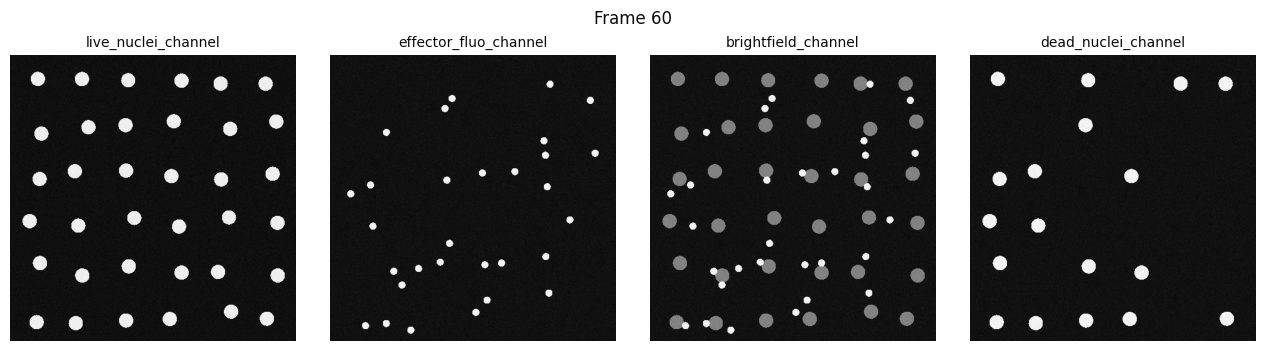

In [5]:
frame = 60
plot_channels(stack, frame, channels)

## 3. Segment both populations

Each population has its own channel on a flat background, so a single
intensity threshold segments it. The histogram of the target channel shows the
two levels, background and cells: the threshold goes between them, and the
spread of the background pixels gives the noise of the images.

{'background': 100.0, 'foreground': 999.0, 'noise': 15.0}


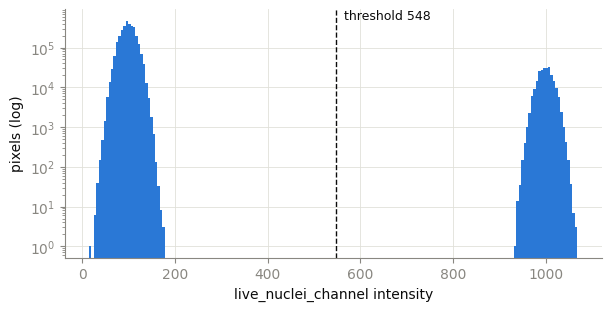

In [6]:
live = stack[..., channels.index("live_nuclei_channel")].ravel()
threshold = 0.5 * (np.percentile(live, 5) + np.percentile(live, 99.5))

ax = panels(size=(6, 3))
ax.hist(live[::7], bins=200, color=TARGETS, log=True)
mark(ax, threshold, f"threshold {threshold:.0f}")
ax.set(xlabel="live_nuclei_channel intensity", ylabel="pixels (log)")

below, above = live[live < threshold], live[live >= threshold]
imaging = {"background": np.median(below), "foreground": np.median(above), "noise": below.std()}
print({k: round(float(v), 1) for k, v in imaging.items()})

Each population is then segmented the standard way: a threshold configuration
(the JSON file the threshold wizard of the GUI writes to `configs/`) is passed
to `segment_from_threshold_at_position`, which segments every frame of the
position and saves the masks in `labels_targets/` and `labels_effectors/`.
The cells of a population never touch, so no watershed is needed.

In [7]:
import json

from celldetective.segmentation import segment_from_threshold_at_position
from celldetective.utils.image_loaders import locate_labels

labels = {}
for population, channel in (("targets", "live_nuclei_channel"), ("effectors", "effector_fluo_channel")):
    instructions = {
        "target_channel": channel,
        "thresholds": [threshold, float(stack.max()) + 1],
        "filters": [],
        "marker_min_distance": 30,
        "marker_footprint_size": 20,
        "feature_queries": [""],
        "equalize_reference": [False, 0],
        "do_watershed": False,
        "fill_holes": True,
    }
    config = os.path.join(EXPERIMENT, "configs", f"threshold_config_{population}.json")
    with open(config, "w") as f:
        json.dump(instructions, f, indent=4)
    segment_from_threshold_at_position(position, population, config)
    labels[population] = locate_labels(position, population=population)
    counts = [len(np.unique(l)) - 1 for l in labels[population]]
    print(f"{population}: {np.median(counts):.0f} cells per frame (min {min(counts)}, max {max(counts)})")

targets: 36 cells per frame (min 36, max 36)


effectors: 30 cells per frame (min 30, max 30)


## 4. Track and measure

The cells are linked from frame to frame with trackpy (an effector moves a few
pixels per frame, so a 12 px search range is enough), then measured: area and
mean intensity in every channel.

In [8]:
import trackpy as tp

from celldetective.measure import measure
from celldetective.tracking import track

tp.quiet()
tables = {}
for population, lbl in labels.items():
    trajectories = track(lbl, btrack_option=False, search_range=12, memory=1, volume=(X, Y))
    tables[population] = measure(
        stack=stack, labels=lbl, trajectories=trajectories,
        channel_names=channels, features=["area", "intensity_mean"],
    )
    print(f"{population}: {tables[population]['TRACK_ID'].nunique()} tracks")

targets: 36 tracks


effectors: 33 tracks


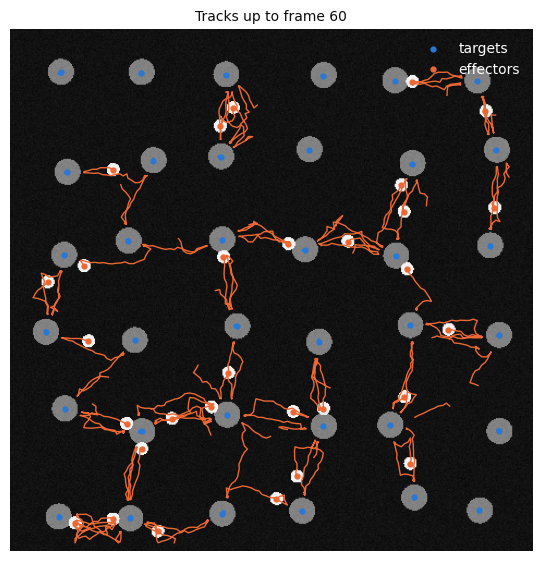

In [9]:
plot_tracks(stack[frame, :, :, channels.index("brightfield_channel")], tables, frame)

## 5. Detect the deaths

Deaths are detected with the threshold signal classification of Celldetective,
in two stages:

1. **Threshold**: at each frame, a target is dead when its mean intensity in
   `dead_nuclei_channel` is above the threshold. This gives a 0/1 status
   signal per track (`status_death`).
2. **Step function fit**: for a track whose status switches, a step function
   (a steep sigmoid) is fitted to the status signal; its midpoint is the death
   time `t_death`, and `class_death` is 0 (the target dies), 1 (it survives)
   or 2 (it is dead from the start).

`classify_tracks_from_query` runs both stages, for an irreversible event.

In [10]:
from celldetective.measure import classify_tracks_from_query

query = f"dead_nuclei_channel_mean > {threshold}"
tables["targets"] = classify_tracks_from_query(tables["targets"], "death", query, irreversible_event=True)

per_target = tables["targets"].groupby("TRACK_ID")[["class_death", "t_death"]].first()
dead = per_target[per_target["class_death"] == 0]
print(f"{len(dead)} of {len(per_target)} targets die during the movie")

24 of 36 targets die during the movie


rounded-up death time = first frame seen dead for 100% of the dying targets


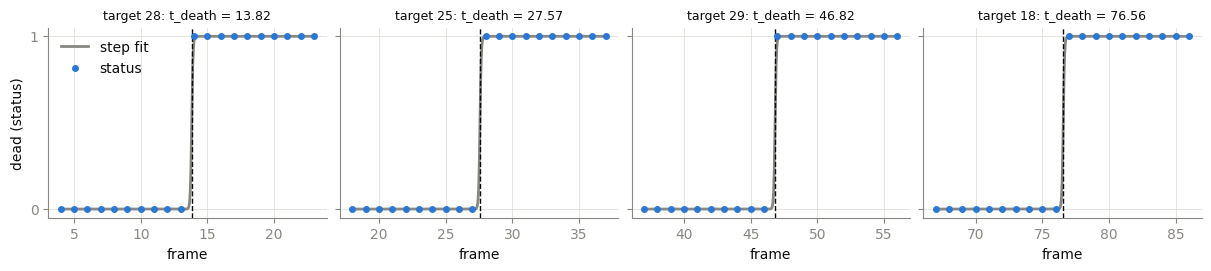

In [11]:
# The thresholded status of a few dying targets, with the step function fitted to it.
examples = dead.sort_values("t_death").iloc[np.linspace(0, len(dead) - 1, 4).astype(int)]
plot_step_fits(tables["targets"], examples, threshold)

# The fitted step sits between the last frame alive and the first frame dead:
# rounded up, it is the first frame where the target is seen dead.
first_dead = (
    tables["targets"][tables["targets"]["dead_nuclei_channel_mean"] > threshold]
    .groupby("TRACK_ID")["FRAME"].min()
)
agree = (np.ceil(dead["t_death"]) == first_dead[dead.index]).mean()
print(f"rounded-up death time = first frame seen dead for {agree:.0%} of the dying targets")

The survival of the targets follows from their death times: `compute_survival`
fits a Kaplan-Meier estimator, with the targets that survive to the end of
the movie as censored observations.

median survival: 57 min; 33% of the targets alive at 99 min


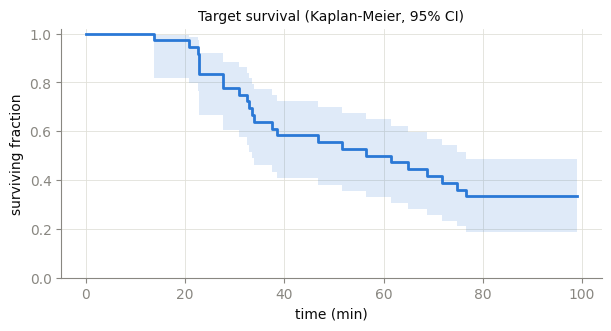

In [12]:
from celldetective.events import compute_survival

tables["targets"]["position"] = position
km = compute_survival(tables["targets"], "class_death", "t_death", FrameToMin=frame_to_min)

ax = panels()
plot_survival(ax, km, band=True)
ax.set(xlabel="time (min)", title="Target survival (Kaplan-Meier, 95% CI)")
survival = km.survival_function_.iloc[:, 0]
print(f"median survival: {km.median_survival_time_:.0f} min; "
      f"{survival.iloc[-1]:.0%} of the targets alive at {survival.index[-1]:.0f} min")

The tables are saved in the position, where the neighborhood and pair tools
read them.

In [13]:
table_dir = os.path.join(position, "output", "tables")
for population, df in tables.items():
    df.to_csv(os.path.join(table_dir, f"trajectories_{population}.csv"), index=False)

## 6. Contacts: neighborhood, pairs and episodes

A target and an effector are in contact when their masks touch or overlap
(a contact neighborhood at 0 px). The pair table then follows every
target–effector pair that met, frame by frame, and
`collapse_pairs_by_episode` cuts each pair's contacts into episodes, with
their start, end and duration.

In [14]:
from celldetective.neighborhood import compute_contact_neighborhood_at_position
from celldetective.relative_measurements import measure_pair_signals_at_position
from celldetective.utils.data_cleaning import collapse_pairs_by_episode

NEIGHBORHOOD = "neighborhood_(targets-effectors)_contact_0_px"
compute_contact_neighborhood_at_position(
    position, distance=[0], population=["targets", "effectors"], img_shape=(Y, X),
    return_tables=False, clear_neigh=True,
)
pairs = measure_pair_signals_at_position(position, {
    "reference": "targets", "neighbor": "effectors", "type": "contact",
    "distance": 0, "description": NEIGHBORHOOD,
})
episodes = collapse_pairs_by_episode(pairs, NEIGHBORHOOD)
complete = episodes[~episodes["left_censored"] & ~episodes["right_censored"]]
print(f"{len(episodes)} contact episodes, {len(complete)} seen from start to end")

157 contact episodes, 144 seen from start to end


recovered contact durations: (4, 12)


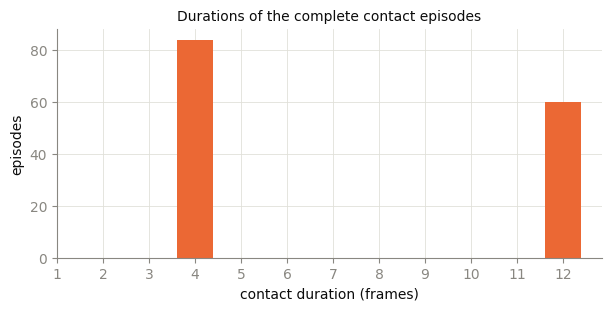

In [15]:
durations = complete["duration"].value_counts().sort_index()
ax = panels(size=(6, 3))
ax.bar(durations.index, durations.to_numpy(), width=0.8, color=EFFECTORS)
ax.set(xlabel="contact duration (frames)", ylabel="episodes", xticks=range(1, int(durations.index.max()) + 1),
       title="Durations of the complete contact episodes")

# The scripted durations are the ones most episodes take; a few others are
# docking cut short by the start or end of a pair's track.
recovered_durations = tuple(sorted(durations[durations > 0.1 * durations.sum()].index))
print("recovered contact durations:", recovered_durations)

## 7. Do contacts kill, and how long after? The contact hazard

`time_varying_table` writes the long table of a survival analysis: one row
per target and frame interval `(t, t + 1]`, with whether the target died in
it and its contact exposure at `t - lag`. Rows stop at the death, so only
targets still alive are at risk.

A lethal hit is not seen at once: the killed target goes on looking alive for
an unknown number of frames before it is seen dead. A death in `(t, t + 1]`
then comes from a contact at `t - N`, `N` frames of incompressible delay
earlier. The lag finds it: a Cox model with the time-varying covariate
`in_contact`, fitted at each lag, compares the death rate of targets that
were in contact `lag` frames earlier with that of targets that were not.
Contacts last several frames, so the hazard ratio rises over the lags that
reach into the lethal contact episode, and peaks at the lag of the lethal
frame itself: the delay.

     hazard_ratio  ci_lower  ci_upper      p
lag                                         
0           2.053     0.865     4.876  0.103
1           2.770     1.155     6.643  0.022
2           3.952     1.578     9.900  0.003
3           6.391     2.467    16.556  0.000
4           6.717     2.566    17.586  0.000
5           9.871     3.252    29.963  0.000
6          10.678     3.741    30.476  0.000
7           3.896     1.452    10.456  0.007
8           3.106     1.249     7.723  0.015
9           2.071     0.840     5.105  0.114
10          1.656     0.639     4.292  0.299
11          1.062     0.373     3.024  0.911
12          1.179     0.406     3.427  0.762
a killed target is seen dead 6 frame(s) later than at once


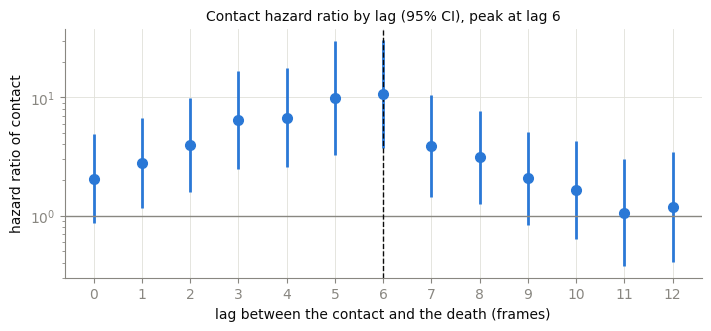

In [16]:
from celldetective.hazard import fit_hazard, time_varying_table

reference = pd.read_csv(os.path.join(table_dir, "trajectories_targets.csv"))


def lag_scan(reference, lags):
    # The hazard ratio of contact, fitted at each lag between the contact and the death.
    fits = [
        fit_hazard(time_varying_table(reference, NEIGHBORHOOD, "death", lag=lag, duration_unit="frame"),
                           ["in_contact"])[1].iloc[0]
        for lag in lags
    ]
    return pd.DataFrame(fits, index=list(lags)).rename_axis("lag")


fits = lag_scan(reference, range(13))
recovered_delay = int(fits["hazard_ratio"].idxmax())
print(fits[["hazard_ratio", "ci_lower", "ci_upper", "p"]].round(3))

ax = panels(size=(7, 3.2))
plot_hazard_ratios(ax, fits)
mark(ax, recovered_delay)
ax.set(xlabel="lag between the contact and the death (frames)",
       title=f"Contact hazard ratio by lag (95% CI), peak at lag {recovered_delay}")
print(f"a killed target is seen dead {recovered_delay} frame(s) later than at once")

At that lag, the death rates are read from the long table directly:

- out of contact, the fraction of intervals ending in a death is the
  background death rate;
- in contact, a target dies either from the contact or from the background:
  $h_\text{contact} = 1 - (1 - p)(1 - h_\text{background})$, which gives the
  death probability per contact frame $p$.

Their 95% intervals come from a bootstrap over targets. A killed target that
is not dead yet stays in the table as at risk, though it can neither be killed
again nor die of the background: with a long delay, this pulls both rates a
little away from their true values.

In [17]:
long_table = time_varying_table(reference, NEIGHBORHOOD, "death", lag=recovered_delay, duration_unit="frame")


def death_rates(table):
    counts = table.groupby("in_contact")["event"].agg(["sum", "size"])
    h_out = counts.loc[0, "sum"] / counts.loc[0, "size"]
    h_in = counts.loc[1, "sum"] / counts.loc[1, "size"]
    return h_out, 1 - (1 - h_in) / (1 - h_out)


background_rate, death_probability = death_rates(long_table)

rng = np.random.default_rng(0)
per_cell = {cell: rows for cell, rows in long_table.groupby("cell")}
cells = list(per_cell)
boot = np.array([
    death_rates(pd.concat([per_cell[c] for c in rng.choice(cells, len(cells))]))
    for _ in range(500)
])
ci = np.percentile(boot, [2.5, 97.5], axis=0)
print(f"{long_table['event'].sum()} deaths over {len(long_table)} target-frames at risk")
print(f"background death rate: {background_rate:.4f}  [{ci[0, 0]:.4f}, {ci[1, 0]:.4f}]")
print(f"death probability per contact frame: {death_probability:.4f}  [{ci[0, 1]:.4f}, {ci[1, 1]:.4f}]")

24 deaths over 1973 target-frames at risk
background death rate: 0.0052  [0.0022, 0.0093]
death probability per contact frame: 0.0320  [0.0144, 0.0535]


## 8. Geometry and motion

- **Radii**: the masks are disks, so $r = \sqrt{\text{area} / \pi}$.
- **Jiggle**: targets fluctuate around a rest position; the spread of each
  target's positions over its track is the jiggle.
- **Effector speed**: the step between consecutive frames of effectors that
  are not docked (out of contact at both frames).

In [18]:
radius = {p: float(np.sqrt(tables[p]["area"].median() / np.pi)) for p in tables}

positions = reference.groupby("TRACK_ID")[["POSITION_X", "POSITION_Y"]]
jiggle = float(np.sqrt((positions.var()).stack().mean()))

in_contact = pairs[pairs[f"status_{NEIGHBORHOOD}"] == 1]
docked = set(zip(in_contact["NEIGHBOR_ID"], in_contact["FRAME"]))
eff = tables["effectors"].sort_values(["TRACK_ID", "FRAME"])
by_track = eff.groupby("TRACK_ID")
step = np.hypot(by_track["POSITION_X"].diff(), by_track["POSITION_Y"].diff())
consecutive = by_track["FRAME"].diff() == 1
free = np.array([(i, f) not in docked and (i, f - 1) not in docked for i, f in zip(eff["TRACK_ID"], eff["FRAME"])])
speed = float(np.median(step[consecutive & free]))

print(f"radii: targets {radius['targets']:.2f} px, effectors {radius['effectors']:.2f} px")
print(f"jiggle: {jiggle:.2f} px")
print(f"effector speed: {speed:.2f} px / frame")

radii: targets 12.01 px, effectors 6.00 px
jiggle: 0.69 px
effector speed: 4.00 px / frame


## 9. Recovered against true

The simulation's parameters, read back from `TRUE`, next to what the analysis
found in the images. The number of cells is the median number of masks per
frame (a track can break, so the number of tracks may be a little higher).

In [19]:
n_cells = {p: int(np.median([len(np.unique(l)) - 1 for l in lbl])) for p, lbl in labels.items()}
rows = [
    ("number of targets", TRUE["n_targets"], n_cells["targets"], "masks per frame"),
    ("number of effectors", TRUE["n_effectors"], n_cells["effectors"], "masks per frame"),
    ("target radius (px)", TRUE["target_radius"], round(radius["targets"], 2), "mask area"),
    ("effector radius (px)", TRUE["effector_radius"], round(radius["effectors"], 2), "mask area"),
    ("target jiggle (px)", TRUE["jiggle"], round(jiggle, 2), "spread of target tracks"),
    ("effector speed (px/frame)", TRUE["effector_speed"], round(speed, 2), "steps of free effectors"),
    ("contact durations (frames)", TRUE["contact_durations"], recovered_durations, "contact episodes"),
    ("death probability per contact frame", TRUE["death_probability"],
     f"{death_probability:.3f} [{ci[0, 1]:.3f}, {ci[1, 1]:.3f}]", "time-varying table at the delay"),
    ("background death rate (per frame)", TRUE["background_death"],
     f"{background_rate:.4f} [{ci[0, 0]:.4f}, {ci[1, 0]:.4f}]", "time-varying table at the delay"),
    ("delay from lethal hit to death (frames)", TRUE["death_delay"], recovered_delay, "Cox model, lag scan"),
    ("background intensity", TRUE["background"], round(imaging["background"], 1), "intensity histogram"),
    ("cell intensity", TRUE["foreground"], round(imaging["foreground"], 1), "intensity histogram"),
    ("noise (std)", TRUE["noise"], round(imaging["noise"], 1), "intensity histogram"),
]
pd.DataFrame(rows, columns=["parameter", "true", "recovered", "from"]).set_index("parameter")

,true,recovered,from
parameter,,,
number of targets,36,36,masks per frame
number of effectors,30,30,masks per frame
target radius (px),12.0,12.01,mask area
effector radius (px),6.0,6.0,mask area
target jiggle (px),0.7,0.69,spread of target tracks
effector speed (px/frame),4.0,4.0,steps of free effectors
contact durations (frames),"(4, 12)","(4, 12)",contact episodes
death probability per contact frame,0.04,"0.032 [0.014, 0.054]",time-varying table at the delay
background death rate (per frame),0.003,"0.0052 [0.0022, 0.0093]",time-varying table at the delay


Each parameter of the simulation is recovered from the images alone. The two
death rates come with a sampling uncertainty: with a few dozen targets, a few
dozen deaths are observed, and the bootstrap intervals show how precisely they
pin the rates down. Increase `n_targets`, `n_frames` or the image size in the
first cell to narrow them; change `death_delay` to see the peak of the lag
scan move with it, or set `death_probability=0` to see the contact hazard
ratio fall back to 1 at every lag.

To compare with the exact contacts and deaths of the simulation, read the
files in the position's `ground_truth/` folder.

# Part II. Killing mechanisms

The simulation can make the killing richer than a constant hit probability.
Each mechanism below is switched on alone in a new experiment, which goes
through the same image analysis as in part I. A way to detect it and to
measure its parameter is then built from Celldetective's outputs: the long
table of the contact hazard, the pair table, the contact episodes and
neighborhoods.

| mechanism | simulation parameter | what it does |
|---|---|---|
| cooperation | `cooperativity` | with `k` effectors on a target, each hits with probability `p * cooperativity ** (k - 1)` |
| contact maturation | `contact_maturation` | an effector can only kill after that many frames docked |
| exhaustion | `lethality_per_kill` | each kill multiplies the effector's hit probability by this factor |
| resistant targets | `resistant_fraction` | that fraction of targets is never killed |
| death of neighbors, direct | `bystander_death` | each dead target nearby kills a live one with this probability per frame |
| death of neighbors, indirect | `recruitment` | effectors prefer targets near dead ones |
| variable delay | `death_delay=(min, max)` | the delay from the lethal hit to the death varies |

The function below runs part I's pipeline on a new experiment: threshold
segmentation, tracking, measurements, death detection, contact neighborhood,
pairs and contact episodes. With `death_radius`, it also counts, for each
target and frame, the dead targets within that radius: a target-target
distance neighborhood whose neighbors are split by their death status.

In [20]:
from scipy.optimize import minimize

from celldetective.neighborhood import compute_neighborhood_at_position


def run_experiment(params, death_radius=None):
    # Simulate an experiment and analyse its images as in part I.
    experiment = os.path.join(tempfile.mkdtemp(prefix="celldetective_mechanism_"), "Experiment")
    position = write_experiment(experiment, simulate_interactions(**params))
    stack = locate_stack(position)
    T, Y, X, C = stack.shape
    tables = {}
    for population, channel in (("targets", "live_nuclei_channel"), ("effectors", "effector_fluo_channel")):
        config = os.path.join(experiment, "configs", f"threshold_config_{population}.json")
        with open(config, "w") as f:
            json.dump({**instructions, "target_channel": channel}, f)
        segment_from_threshold_at_position(position, population, config)
        lbl = locate_labels(position, population=population)
        trajectories = track(lbl, btrack_option=False, search_range=12, memory=1, volume=(X, Y))
        tables[population] = measure(stack=stack, labels=lbl, trajectories=trajectories,
                                     channel_names=channels, features=["area", "intensity_mean"])
    tables["targets"] = classify_tracks_from_query(tables["targets"], "death", query, irreversible_event=True)
    folder = os.path.join(position, "output", "tables")
    for population, df in tables.items():
        df.to_csv(os.path.join(folder, f"trajectories_{population}.csv"), index=False)

    compute_contact_neighborhood_at_position(position, distance=[0], population=["targets", "effectors"],
                                             img_shape=(Y, X), return_tables=False, clear_neigh=True)
    if death_radius is not None:
        # Neighbors split by their death status: s1 counts the dead ones.
        compute_neighborhood_at_position(
            position, distance=[death_radius], population=["targets", "targets"], img_shape=(Y, X),
            return_tables=False, clear_neigh=False,
            neighborhood_kwargs={"mode": "self", "status": [None, "status_death"],
                                 "not_status_option": [False, False], "include_dead_weight": True,
                                 "compute_cum_sum": False, "attention_weight": True, "symmetrize": False})
    pair_table = measure_pair_signals_at_position(position, {
        "reference": "targets", "neighbor": "effectors", "type": "contact",
        "distance": 0, "description": NEIGHBORHOOD})
    reference = pd.read_csv(os.path.join(folder, "trajectories_targets.csv"))
    return {"reference": reference, "pairs": pair_table, "params": params,
            "long": time_varying_table(reference, NEIGHBORHOOD, "death", duration_unit="frame")}


EPS = 1e-12


def binomial_nll(h, events, n=1):
    # Negative log-likelihood of event counts out of n trials of probability h.
    h = np.clip(h, EPS, 1 - EPS)
    return -np.sum(events * np.log(h) + (n - events) * np.log(1 - h))


def bootstrap(groups, estimate, n=200, seed=0):
    # 95% interval of an estimate over resamples of independent units (cells, effectors).
    rng = np.random.default_rng(seed)
    keys = list(groups)
    values = [estimate(pd.concat([groups[k] for k in rng.choice(keys, len(keys))])) for _ in range(n)]
    return np.percentile(np.array(values), [2.5, 97.5], axis=0)


BIG = dict(shape=(640, 640), n_frames=100, n_targets=81, contact_durations=(4, 12), seed=1)
SMALL = dict(shape=(480, 480), n_frames=100, n_targets=36, n_effectors=30, contact_durations=(4, 12), seed=1)
mechanisms = []  # (mechanism, parameter, true, recovered, method)

## 10. Cooperation between effectors

**Simulation**: many effectors, so that targets often have several at once;
each effector on a target hits on its own (`per_effector_hits=True`), with a
probability multiplied by `cooperativity` for each other effector there.

**Detection**: the long table has, for every target and frame, the number of
effectors in contact (`n_neighbors`, the inclusive count of the contact
neighborhood). The fraction of frames followed by a death, per number of
effectors `k`, is the hit probability of a target with `k` effectors. If
effectors act independently, it is $1 - (1 - p)^k$; with cooperativity
$c$, $1 - (1 - p\,c^{k-1})^k$. Fitting both curves to the counts gives `p`
and `c`.

             sum  size    rate
n_neighbors                   
0              0  1751  0.0000
1             17   927  0.0183
2             31   411  0.0754
3             18    54  0.3333
4              6     9  0.6667
cooperativity: 2.51 [1.98, 3.58], p per effector 0.0170


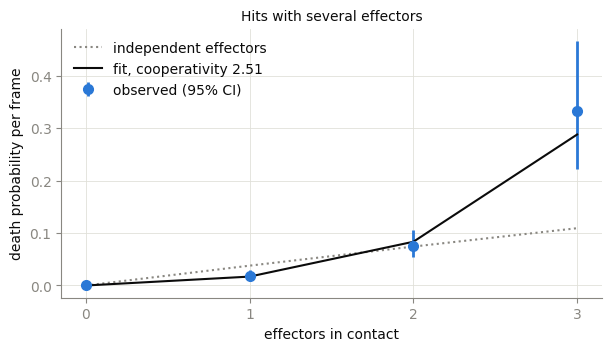

In [21]:
coop = run_experiment({**BIG, "n_effectors": 160, "death_probability": 0.015,
                       "per_effector_hits": True, "cooperativity": 2.5})


def cooperation_hazard(k, b, p, c):
    # Death probability per frame with k effectors in contact, each hitting with probability p * c ** (k - 1).
    hit = np.where(k > 0, 1 - (1 - np.clip(p * c ** (k - 1), 0, 1)) ** k, 0.0)
    return 1 - (1 - b) * (1 - hit)


def fit_cooperation(table):
    counts = table.groupby(table["n_neighbors"].astype(int))["event"].agg(["sum", "size"])
    k, e, n = counts.index.to_numpy(), counts["sum"].to_numpy(), counts["size"].to_numpy()
    fit = minimize(lambda th: binomial_nll(cooperation_hazard(k, *th), e, n), [0.001, 0.01, 1.0],
                   bounds=[(0, 0.5), (1e-5, 0.5), (0.05, 20)], method="L-BFGS-B")
    independent = minimize(lambda th: binomial_nll(cooperation_hazard(k, *th, 1.0), e, n), [0.001, 0.01],
                           bounds=[(0, 0.5), (1e-5, 0.5)], method="L-BFGS-B")
    return fit.x, independent.x, counts


(b_c, p_c, c_hat), (b_i, p_i), counts = fit_cooperation(coop["long"])
c_ci = bootstrap(dict(list(coop["long"].groupby("cell"))), lambda t: fit_cooperation(t)[0][2])

shown = counts[counts["size"] >= 20]
ax = panels(size=(6, 3.4))
plot_rates(ax, shown)
k = np.arange(shown.index.max() + 1)
ax.plot(k, cooperation_hazard(k, b_i, p_i, 1.0), ls=":", color=MUTED, lw=1.5, label="independent effectors")
ax.plot(k, cooperation_hazard(k, b_c, p_c, c_hat), color=INK, lw=1.5, label=f"fit, cooperativity {c_hat:.2f}")
ax.set(xticks=k, xlabel="effectors in contact", ylabel="death probability per frame",
       title="Hits with several effectors")
ax.legend(loc="upper left")
print(counts.assign(rate=counts["sum"] / counts["size"]).round(4))
print(f"cooperativity: {c_hat:.2f} [{c_ci[0]:.2f}, {c_ci[1]:.2f}], p per effector {p_c:.4f}")
mechanisms.append(("cooperation", "cooperativity", 2.5, f"{c_hat:.2f} [{c_ci[0]:.2f}, {c_ci[1]:.2f}]",
                   "hit rate by number of effectors"))

## 11. Contact maturation

**Simulation**: an effector can only kill once it has been docked for
`contact_maturation` frames.

**Detection**: the long table holds `ongoing_contact`, the number of frames
the current contact has lasted. The hit probability per frame, by contact
age, is zero for young contacts and constant after. The age at which it
switches is found as a change point: for each candidate `m`, the likelihood of
a model with no hits up to age `m` and a constant probability after; the best
`m` is the maturation time.

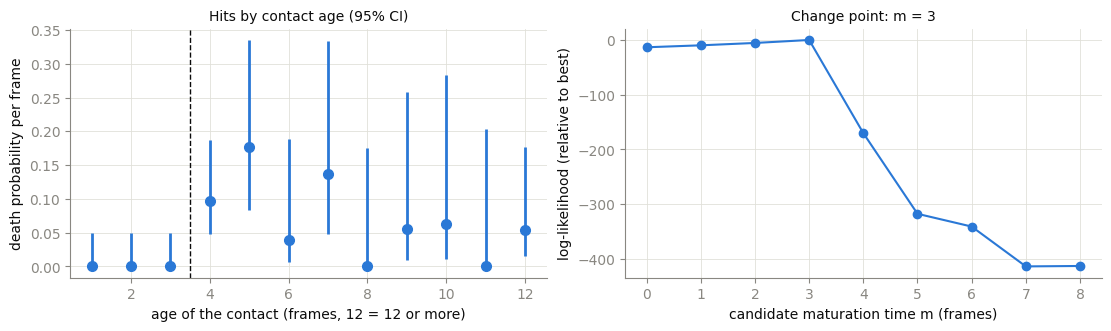

In [22]:
mat = run_experiment({**SMALL, "death_probability": 0.08, "contact_maturation": 3})
table = mat["long"]
background = table.loc[table["in_contact"] == 0, "event"].mean()
inc = table[table["in_contact"] == 1]
age, ev = inc["ongoing_contact"].to_numpy(), inc["event"].to_numpy()
profile = []
for m in range(9):
    mature = age > m
    p = ev[mature].mean() if mature.any() else 0.0
    profile.append(-binomial_nll(np.where(mature, 1 - (1 - background) * (1 - p), background), ev))
# Contact age counts from 1 (the first frame); docked for m frames before = age m + 1.
m_hat = int(np.argmax(profile))

by_age = inc.groupby(inc["ongoing_contact"].clip(upper=12).astype(int))["event"].agg(["sum", "size"])
axes = panels(2, (5.5, 3.2))
plot_rates(axes[0], by_age, label=None)
mark(axes[0], m_hat + 0.5)
axes[0].set(xlabel="age of the contact (frames, 12 = 12 or more)", ylabel="death probability per frame",
            title="Hits by contact age (95% CI)")
axes[1].plot(range(9), np.array(profile) - max(profile), "o-", color=TARGETS)
axes[1].set(xlabel="candidate maturation time m (frames)", ylabel="log-likelihood (relative to best)",
            title=f"Change point: m = {m_hat}")
mechanisms.append(("contact maturation", "contact_maturation", 3, m_hat, "change point of the hit rate by contact age"))

## 12. Effector exhaustion

**Simulation**: each kill multiplies the effector's hit probability by
`lethality_per_kill` (here 0.5: exhaustion). Many targets per effector and a
longer movie let effectors kill several times.

**Detection**: the pair table tells which effector was on which target at
each frame. A death at frame `T` comes from a hit at `T - 1`: when one effector
alone was on the target then, the kill is its own. For each effector, every
frame it spends alone on a live target is a trial, a success when it kills;
its hit probability is modelled as $p\,\lambda^{n}$, `n` being its kills so
far, and `p` and $\lambda$ are fitted by maximum likelihood. Frames with
several effectors on the target are left out, as their kill cannot be
attributed.

Few effectors kill more than twice in a movie, so the interval on $\lambda$
stays wide even with 200 frames: the estimate is right, but it would take
longer movies or more positions to rule out that effectors do not exhaust.

25 attributed kills over 366 effector-frames
lethality per kill: 0.55 [0.18, 1.52]


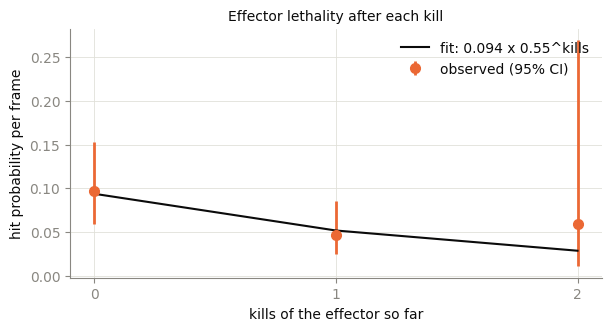

In [23]:
exh = run_experiment({**BIG, "n_frames": 200, "n_effectors": 16, "death_probability": 0.1,
                      "per_effector_hits": True, "lethality_per_kill": 0.5})

status_col = f"status_{NEIGHBORHOOD}"
contacts = exh["pairs"].loc[exh["pairs"][status_col] == 1, ["REFERENCE_ID", "NEIGHBOR_ID", "FRAME"]]
alone = contacts.groupby(["REFERENCE_ID", "FRAME"])["NEIGHBOR_ID"].transform("size") == 1
deaths = exh["reference"].groupby("TRACK_ID")[["class_death", "t_death"]].first()
hit = (np.ceil(deaths.loc[deaths["class_death"] == 0, "t_death"]) - 1).rename("hit")
trials = contacts[alone].merge(hit, left_on="REFERENCE_ID", right_index=True, how="left")
trials = trials[trials["hit"].isna() | (trials["FRAME"] <= trials["hit"])].copy()  # target alive, not yet hit
trials["kill"] = (trials["FRAME"] == trials["hit"]).astype(int)
kills = trials.loc[trials["kill"] == 1, ["NEIGHBOR_ID", "FRAME"]]
trials["kills_before"] = [((kills["NEIGHBOR_ID"] == e) & (kills["FRAME"] < f)).sum()
                          for e, f in zip(trials["NEIGHBOR_ID"], trials["FRAME"])]


def fit_exhaustion(t):
    e, n = t["kill"].to_numpy(), t["kills_before"].to_numpy()
    return minimize(lambda th: binomial_nll(th[0] * th[1] ** n, e), [0.05, 1.0],
                    bounds=[(1e-4, 0.9), (0.01, 10)], method="L-BFGS-B").x


p_e, lam = fit_exhaustion(trials)
lam_ci = bootstrap(dict(list(trials.groupby("NEIGHBOR_ID"))), lambda t: fit_exhaustion(t)[1])

by_kills = trials.groupby("kills_before")["kill"].agg(["sum", "size"])
by_kills = by_kills[by_kills["size"] >= 10]
ax = panels()
plot_rates(ax, by_kills, color=EFFECTORS)
n = np.arange(by_kills.index.max() + 1)
ax.plot(n, p_e * lam ** n, color=INK, lw=1.5, label=f"fit: {p_e:.3f} x {lam:.2f}^kills")
ax.set(xticks=n, xlabel="kills of the effector so far", ylabel="hit probability per frame",
       title="Effector lethality after each kill")
ax.legend()
print(f"{int(trials['kill'].sum())} attributed kills over {len(trials)} effector-frames")
print(f"lethality per kill: {lam:.2f} [{lam_ci[0]:.2f}, {lam_ci[1]:.2f}]")
mechanisms.append(("exhaustion", "lethality_per_kill", 0.5, f"{lam:.2f} [{lam_ci[0]:.2f}, {lam_ci[1]:.2f}]",
                   "effector kill history, pair table"))

## 13. Resistant targets

**Simulation**: a fraction of the targets is never killed, whatever its
contacts.

**Detection**: a resistant target survives however much contact it gets, so
the survival curve levels off, but a target can also survive because it was
seldom touched. The long table gives each target's exposure `E`, its number
of frames in contact while alive. A mixture ("cure") model separates the two:
a target is resistant with probability `f`; otherwise each frame of contact
kills it with probability `p`. A target that dies at its `E`-th frame of
contact has the likelihood $(1 - f)\,p\,(1 - p)^{E - 1}$, one that survives
$E$ frames of contact $f + (1 - f)(1 - p)^E$.

resistant fraction: 0.38 [0.20, 0.53], p per contact frame 0.090


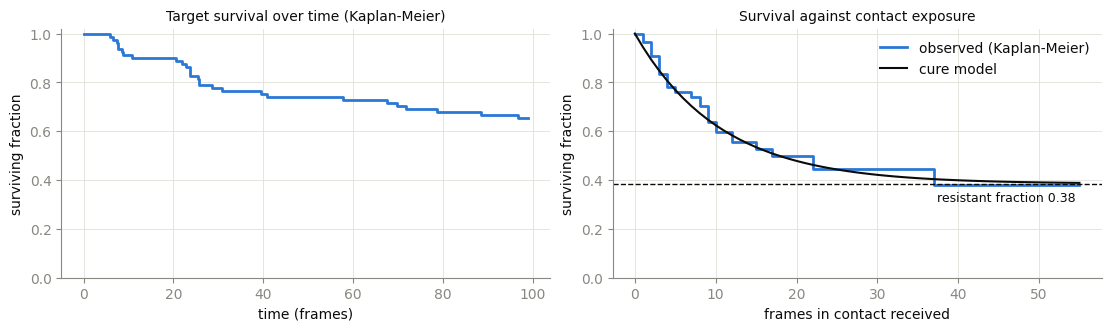

In [24]:
from lifelines import KaplanMeierFitter

res = run_experiment({**BIG, "n_effectors": 40, "death_probability": 0.1, "resistant_fraction": 0.3})
per_cell = res["long"].groupby("cell").agg(E=("in_contact", "sum"), died=("event", "max"))


def fit_resistance(t):
    E, d = t["E"].to_numpy(), t["died"].to_numpy()

    def nll(th):
        f, p = th
        lik = np.where(d == 1, (1 - f) * p * (1 - p) ** np.maximum(E - 1, 0), f + (1 - f) * (1 - p) ** E)
        return -np.sum(np.log(np.clip(lik, EPS, None)))

    return minimize(nll, [0.2, 0.05], bounds=[(0, 0.99), (1e-4, 0.9)], method="L-BFGS-B").x


f_hat, p_r = fit_resistance(per_cell)
f_ci = bootstrap({c: per_cell.loc[[c]] for c in per_cell.index}, lambda t: fit_resistance(t)[0])

res["reference"]["position"] = "resistance"
km_time = compute_survival(res["reference"], "class_death", "t_death")
# With exposure as the clock, the cure model predicts the survival curve itself.
km_exposure = KaplanMeierFitter().fit(per_cell["E"], event_observed=per_cell["died"])

axes = panels(2, (5.5, 3.2))
plot_survival(axes[0], km_time)
axes[0].set(xlabel="time (frames)", title="Target survival over time (Kaplan-Meier)")
plot_survival(axes[1], km_exposure, label="observed (Kaplan-Meier)")
E = np.arange(0, int(per_cell["E"].max()) + 1)
axes[1].plot(E, f_hat + (1 - f_hat) * (1 - p_r) ** E, color=INK, lw=1.5, label="cure model")
axes[1].axhline(f_hat, color=INK, ls="--", lw=1)
axes[1].text(E.max(), f_hat - 0.03, f"resistant fraction {f_hat:.2f} ", ha="right", va="top", fontsize=9)
axes[1].set(xlabel="frames in contact received", title="Survival against contact exposure")
axes[1].legend(loc="upper right")
print(f"resistant fraction: {f_hat:.2f} [{f_ci[0]:.2f}, {f_ci[1]:.2f}], p per contact frame {p_r:.3f}")
mechanisms.append(("resistant targets", "resistant_fraction", 0.3, f"{f_hat:.2f} [{f_ci[0]:.2f}, {f_ci[1]:.2f}]",
                   "cure model on contact exposure"))

## 14. Death of neighboring targets: direct or through the effectors?

Two experiments where a target's death makes its neighbors die more:

- **direct**: each dead target within 90 px kills a live one with probability
  `bystander_death` per frame, without any contact (a toxic release, say);
- **indirect**: dead targets attract effectors (`recruitment`), so their
  neighbors get more contacts; the contacts kill as usual.

Both have a small background death rate, so that deaths out of contact exist
and the effect of contact stays finite in the Cox models.

**Detection**: the target-target neighborhood counts, for each target and
frame, its dead neighbors within 90 px. Carried into the long table as a
covariate (`extra_covariates`), it enters two Cox models:

- alone, its hazard ratio says whether deaths cluster around dead targets,
  which both mechanisms do;
- next to `in_contact`, it says whether the clustering remains once the
  contacts are accounted for: only a direct effect does.

The direct effect is also measured: out of contact, the death probability per
frame with `m` dead neighbors is $1 - (1 - b)(1 - q)^m$, fitted for the
background `b` and the bystander probability `q`.

,deaths,HR dead neighbors,HR dead neighbors | contact,q (out of contact),true q
experiment,,,,,
direct,71,"1.52 [1.14, 2.01]","1.52 [1.15, 2.01]",0.0091,0.01
indirect,42,"1.74 [1.23, 2.45]","1.16 [0.79, 1.69]",0.0000,0.00


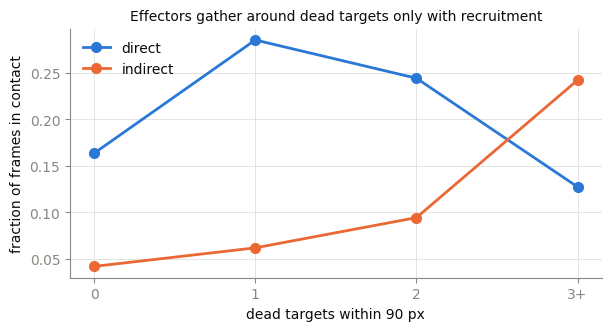

In [25]:
DEAD = "inclusive_count_s1_neighborhood_self_circle_90_px"
NEIGHBORS = {**BIG, "n_effectors": 60, "death_probability": 0.05, "background_death": 0.003,
             "bystander_radius": 90}
bystander = {
    "direct": run_experiment({**NEIGHBORS, "bystander_death": 0.01}, death_radius=90),
    "indirect": run_experiment({**NEIGHBORS, "recruitment": 5.0}, death_radius=90),
}
rows, contact_by_dead = [], {}
for name, run in bystander.items():
    table = time_varying_table(run["reference"], NEIGHBORHOOD, "death", duration_unit="frame",
                               extra_covariates=[DEAD]).rename(columns={DEAD: "dead_neighbors"})
    _, alone_fit = fit_hazard(table, ["dead_neighbors"], penalizer=0.001)
    _, adjusted = fit_hazard(table, ["dead_neighbors", "in_contact"], penalizer=0.001)
    out = table[table["in_contact"] == 0]
    m, e = out["dead_neighbors"].to_numpy(), out["event"].to_numpy()
    b, q = minimize(lambda th: binomial_nll(1 - (1 - th[0]) * (1 - th[1]) ** m, e), [0.001, 0.005],
                    bounds=[(0, 0.5), (0, 0.5)], method="L-BFGS-B").x
    hr = lambda s: f"{s['hazard_ratio']:.2f} [{s['ci_lower']:.2f}, {s['ci_upper']:.2f}]"
    rows.append({"experiment": name, "deaths": int(table["event"].sum()),
                 "HR dead neighbors": hr(alone_fit.iloc[0]),
                 "HR dead neighbors | contact": hr(adjusted.iloc[0]),
                 "q (out of contact)": round(q, 4), "true q": run["params"].get("bystander_death", 0.0)})
    contact_by_dead[name] = table.groupby(table["dead_neighbors"].clip(upper=3).astype(int))["in_contact"].mean()
    mechanisms.append((f"neighbor death, {name}", "bystander_death", run["params"].get("bystander_death", 0.0),
                       round(q, 4), "deaths out of contact by dead neighbors"))

ax = panels()
for (name, series), color in zip(contact_by_dead.items(), (TARGETS, EFFECTORS)):
    ax.plot(series.index, series.to_numpy(), "o-", color=color, ms=7, lw=2, label=name)
ax.set_xticks(range(4), ["0", "1", "2", "3+"])
ax.set(xlabel="dead targets within 90 px", ylabel="fraction of frames in contact",
       title="Effectors gather around dead targets only with recruitment")
ax.legend()
pd.DataFrame(rows).set_index("experiment")

Both experiments show deaths clustering around dead targets (hazard ratio of
the dead neighbors above 1). Once `in_contact` is in the model, the effect
remains in the direct experiment and vanishes in the indirect one: there, the
neighbors of dead targets die more only because they are touched more, as
the fraction of frames in contact shows. The deaths out of contact measure
the direct effect, and find none in the indirect experiment.

## 15. A variable delay between the lethal hit and the death

**Simulation**: the delay of each kill is drawn uniformly between a minimum
and a maximum (`death_delay=(2, 8)`).

**Detection**: the lag scan of part I no longer has a sharp peak but a
plateau over the delays. They are measured by a model of the long table: the
death probability of a row `(t, t + 1]` is
$b + p \cdot s_{lo,hi}(t)$, where $s_{lo,hi}(t)$ is the share of the frames
`t - hi` to `t - lo` the target spent in contact. For each candidate range
`[lo, hi]`, `b` and `p` are fitted; the range with the highest likelihood is
the delay range.

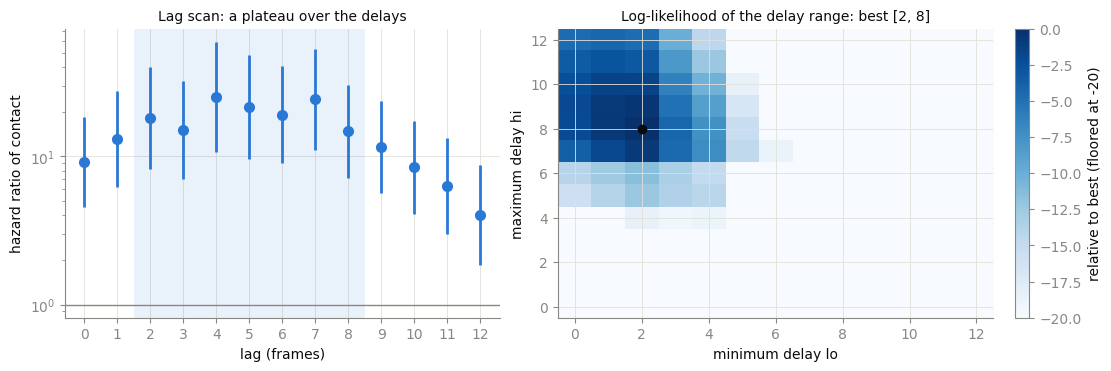

In [26]:
dly = run_experiment({**BIG, "n_effectors": 40, "death_probability": 0.06, "death_delay": (2, 8)})
K = 12
contact = (dly["reference"].set_index(["TRACK_ID", "FRAME"])[f"inclusive_count_{NEIGHBORHOOD}"] > 0).astype(float)
long = dly["long"]
past = np.array([[contact.get((track, t - k), 0.0) for k in range(K + 1)]
                 for track, t in zip(long["TRACK_ID"], long["start"].astype(int))])
y = long["event"].to_numpy()

surface = np.full((K + 1, K + 1), np.nan)
for lo in range(K + 1):
    for hi in range(lo, K + 1):
        share = past[:, lo:hi + 1].mean(axis=1)
        fit = minimize(lambda th: binomial_nll(th[0] + (1 - th[0]) * th[1] * share, y), [0.001, 0.05],
                       bounds=[(0, 0.5), (1e-5, 0.99)], method="L-BFGS-B")
        surface[lo, hi] = -fit.fun
lo_hat, hi_hat = np.unravel_index(np.nanargmax(surface), surface.shape)

lag_fits = lag_scan(dly["reference"], range(K + 1))

axes = panels(2, (5.5, 3.6))
plot_hazard_ratios(axes[0], lag_fits)
axes[0].axvspan(lo_hat - 0.5, hi_hat + 0.5, color=TARGETS, alpha=0.1, lw=0)
axes[0].set(xlabel="lag (frames)", title="Lag scan: a plateau over the delays")
rel = surface - np.nanmax(surface)
im = axes[1].imshow(np.where(rel > -20, rel, -20).T, origin="lower", cmap="Blues", aspect="auto")
axes[1].plot(lo_hat, hi_hat, "o", color=INK)
axes[1].set(xlabel="minimum delay lo", ylabel="maximum delay hi",
            title=f"Log-likelihood of the delay range: best [{lo_hat}, {hi_hat}]")
axes[1].figure.colorbar(im, ax=axes[1], label="relative to best (floored at -20)")
mechanisms.append(("variable delay", "death_delay", (2, 8), (int(lo_hat), int(hi_hat)), "likelihood of the delay range"))

## 16. Mechanisms: recovered against true

In [27]:
pd.DataFrame(mechanisms, columns=["mechanism", "parameter", "true", "recovered", "from"]).set_index("mechanism")

,parameter,true,recovered,from
mechanism,,,,
cooperation,cooperativity,2.5,"2.51 [1.98, 3.58]",hit rate by number of effectors
contact maturation,contact_maturation,3,3,change point of the hit rate by contact age
exhaustion,lethality_per_kill,0.5,"0.55 [0.18, 1.52]","effector kill history, pair table"
resistant targets,resistant_fraction,0.3,"0.38 [0.20, 0.53]",cure model on contact exposure
"neighbor death, direct",bystander_death,0.01,0.0091,deaths out of contact by dead neighbors
"neighbor death, indirect",bystander_death,0.0,0.0,deaths out of contact by dead neighbors
variable delay,death_delay,"(2, 8)","(2, 8)",likelihood of the delay range


Each mechanism leaves a signature the Celldetective outputs can catch, and its
parameter is recovered within its uncertainty. Some need more data than
others: cooperation needs crowded targets, exhaustion effectors that kill
several times, the resistant fraction many targets. With real data, these
are the experiment sizes to aim for before trusting the estimates.

# Part III. Attraction or chance?

Effectors that roam at random also meet the targets, and if they stay on the
targets once they touch them, contacts pile up just as if the effectors were
attracted. Counting contacts cannot tell the two cases apart; the way the
effectors *arrive* can. `celldetective.attraction` compares the real tracks
with a null model, the same tracks shifted as a block by a random offset
(wrapping around the field): the shifted effectors keep their speeds, turns
and pauses, but their positions no longer depend on the targets.

- `arrival_test`: the fraction of the steps a free effector takes that end in
  contact with a target, against the same fraction for the shifted tracks (a
  permutation test). Steps taken in contact are not counted, so a long stay on
  the targets does not look like attraction.
- `approach_bias`: by distance to the nearest target, the mean cosine of the
  angle between an effector's step and the direction of that target: 0 for a
  blind effector, above 0 when effectors head for the targets.

Three experiments, four positions each, differ only by `attraction`, the
chance that a wandering effector heads for a target. In all three,
`capture=True`: a wandering effector that bumps into a target docks to it.

- **blind**: `attraction=0`, every contact is a chance encounter;
- **attracted**: `attraction=1`, effectors head for a target after each
  wander;
- **recruited**: blind for the first 50 frames, attracted after, as when
  recruitment starts during the movie.

The images go through the segmentation and tracking of part I.

In [ ]:
from celldetective.attraction import approach_bias, arrival_test

ONSET = 50
MOTION = dict(shape=(480, 480), n_frames=100, n_targets=36, n_effectors=30, contact_durations=(4, 12),
              capture=True)
ATTRACTION = {"blind": 0.0, "attracted": 1.0, "recruited": np.r_[np.zeros(ONSET), np.ones(100 - ONSET)]}
SEEDS = range(4)  # one position per seed


def tracked_positions(params, seeds):
    # Simulate one position per seed, segment and track it as in part I; the tables of all positions.
    tables = {"targets": [], "effectors": []}
    for seed in seeds:
        experiment = os.path.join(tempfile.mkdtemp(prefix="celldetective_attraction_"), "Experiment")
        pos = write_experiment(experiment, simulate_interactions(**params, seed=seed))
        for population, channel in (("targets", "live_nuclei_channel"), ("effectors", "effector_fluo_channel")):
            config = os.path.join(experiment, "configs", f"threshold_config_{population}.json")
            with open(config, "w") as f:
                json.dump({**instructions, "target_channel": channel}, f)
            segment_from_threshold_at_position(pos, population, config)
            lbl = locate_labels(pos, population=population)
            trajectories = track(lbl, btrack_option=False, search_range=12, memory=1, volume=(X, Y))
            tables[population].append(trajectories.assign(position=seed))
    return {p: pd.concat(dfs, ignore_index=True) for p, dfs in tables.items()}


runs = {name: tracked_positions({**MOTION, "attraction": a}, SEEDS) for name, a in ATTRACTION.items()}
FIELD = MOTION["shape"]
for name, run in runs.items():
    print(f"{name}: {run['effectors'].groupby('position')['TRACK_ID'].nunique().sum()} effector tracks "
          f"in {len(SEEDS)} positions")

blind: 122 effector tracks in 4 positions
attracted: 142 effector tracks in 4 positions
recruited: 124 effector tracks in 4 positions


### The contact distance

Shifted tracks have no masks, so contact is decided from the centres: an
effector touches a target when the distance between their centres is below
`contact_distance`. The real tracks are scored the same way.

The distance must reach as far as the effectors catch the targets. An
effector that grabs a target it only grazes ends up in contact from a
distance at which a shifted track just passes by, and blind effectors then
look attracted. The distances from the effectors to their nearest target
show where to put it: docked effectors sit just inside the sum of the radii,
and free effectors never come closer than the distance at which they are
caught. There is a gap between the two, and `contact_distance` goes just
below its upper edge: every effector that comes that close is caught.

gap: 16.25 to 20.75 px; contact distance: 20.50 px


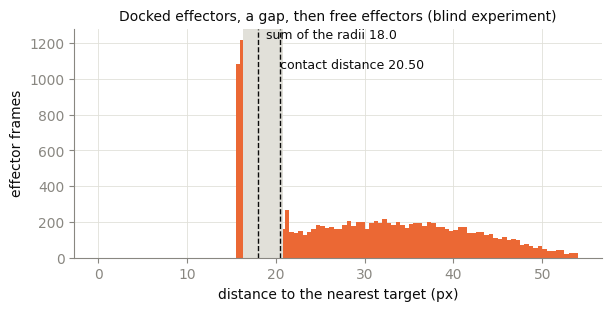

In [ ]:
from scipy.spatial import cKDTree


def nearest_target_distances(run):
    # Distance from each effector to the nearest target of its frame and position.
    out = []
    for (pos, frame), eff in run["effectors"].groupby(["position", "FRAME"]):
        tg = run["targets"][(run["targets"]["position"] == pos) & (run["targets"]["FRAME"] == frame)]
        out.append(cKDTree(tg[["POSITION_X", "POSITION_Y"]]).query(eff[["POSITION_X", "POSITION_Y"]])[0])
    return np.concatenate(out)


distances = nearest_target_distances(runs["blind"])
r_sum = radius["targets"] + radius["effectors"]
# The longest run of empty bins around the sum of the radii is the gap; the
# contact distance sits just below its upper end, the closest a free effector comes.
WIDTH = 0.25
edges = np.arange(0, 2 * r_sum, WIDTH)
counts, _ = np.histogram(distances, edges)
empty = np.r_[0, (counts == 0) & (edges[:-1] > r_sum - 6) & (edges[:-1] < r_sum + 10), 0]
starts, ends = np.flatnonzero(np.diff(empty) == 1), np.flatnonzero(np.diff(empty) == -1)
gap = np.argmax(ends - starts)
gap_low, gap_high = edges[starts[gap]], edges[ends[gap]]
CONTACT = float(gap_high - WIDTH)

ax = panels(size=(6, 3))
ax.hist(distances, bins=np.arange(0, 3 * r_sum, 0.5), color=EFFECTORS)
ax.axvspan(gap_low, gap_high, color=GRID, lw=0)
mark(ax, r_sum, f"sum of the radii {r_sum:.1f}")
mark(ax, CONTACT, f"\n\ncontact distance {CONTACT:.2f}")
ax.set(xlabel="distance to the nearest target (px)", ylabel="effector frames",
       title="Docked effectors, a gap, then free effectors (blind experiment)")
print(f"gap: {gap_low:.2f} to {gap_high:.2f} px; contact distance: {CONTACT:.2f} px")

### Do effectors arrive more often than chance?

The arrival test runs on each experiment, with 199 shifted copies of each
position. Each position gets its own test, and a pooled test adds up the
positions, each shifted on its own. Report the positions rather than the
cells: cells of one field share its geometry and history, so they are not
independent replicates.

,arrivals,free_steps,rate,null_rate,ratio,p_value
blind,314,9602,0.032702,0.033694,0.970557,0.675
attracted,655,7081,0.092501,0.035424,2.611223,0.005
recruited,487,8458,0.057579,0.034288,1.679282,0.005


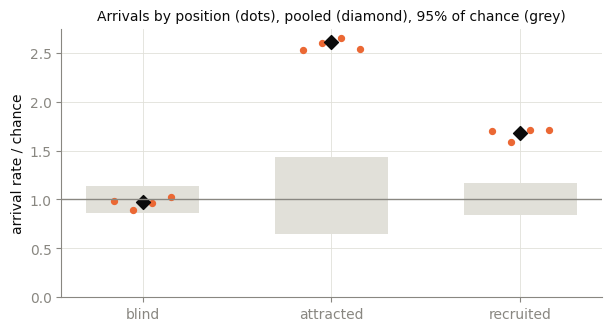

In [ ]:
arrivals = {name: arrival_test(run["targets"], run["effectors"], CONTACT, shape=FIELD, n_shifts=199)
            for name, run in runs.items()}

ax = panels(size=(6, 3.2))
for k, (name, result) in enumerate(arrivals.items()):
    per_position = result[result["position"] != "all"]
    pooled = result[result["position"] == "all"].iloc[0]
    ax.fill_between([k - 0.3, k + 0.3], pooled["null_low"] / pooled["null_rate"],
                    pooled["null_high"] / pooled["null_rate"], color=GRID, lw=0)
    ax.scatter(k + np.linspace(-0.15, 0.15, len(per_position)), per_position["ratio"], color=EFFECTORS, s=18)
    ax.scatter(k, pooled["ratio"], color=INK, s=50, marker="D")
ax.axhline(1, color=MUTED, lw=1)
ax.set_xticks(range(len(arrivals)), list(arrivals))
ax.set(ylabel="arrival rate / chance", ylim=(0, None),
       title="Arrivals by position (dots), pooled (diamond), 95% of chance (grey)")
pd.DataFrame({name: r[r["position"] == "all"].iloc[0][["arrivals", "free_steps", "rate", "null_rate", "ratio",
                                                       "p_value"]]
              for name, r in arrivals.items()}).T

Blind effectors arrive as often as their shifted copies: their contacts
are chance encounters, however many there are. Attracted effectors arrive
about 2.6 times as often as chance, in every position. Recruited effectors,
attracted for half of the movie, fall in between.

A real attraction holds whatever the contact distance, as long as it reaches
the capture range. Below it, blind effectors look attracted, for the reason
given above:

In [ ]:
scan = {d: {name: arrival_test(run["targets"], run["effectors"], d, shape=FIELD, n_shifts=99).iloc[-1]["ratio"]
            for name, run in runs.items() if name != "recruited"}
        for d in (r_sum, CONTACT, CONTACT + 3, CONTACT + 6)}
pd.DataFrame(scan).T.rename_axis("contact distance (px)").round(2)

,blind,attracted
contact distance (px),,
18.005514,1.18,3.18
20.500000,0.97,2.65
23.500000,1.05,2.91
26.500000,1.12,3.13


Below the gap (the sum of the radii), blind effectors come out about 20%
above chance. From the gap on, they stay within about 10% of chance, while
attracted effectors stay near 3. With real data, run the same scan on a
control condition: the size of the effect, against the control, is what
counts, more than its distance to 1.

### Do effectors head for the targets?

The approach bias looks at the motion itself: free effectors that head for
targets have a positive mean cosine to the nearest one, out to the range of
the attraction. The steps that end in contact are left out (docking moves an
effector's centre towards its target, however it got there). Steps near the
edges of the field are left out too. The shifted tracks give the band the
cosine stays in by chance, which also accounts for the biases of the method
itself: just outside the contact distance, the remaining steps are the ones
that did not end in contact, so they lean away from the target.

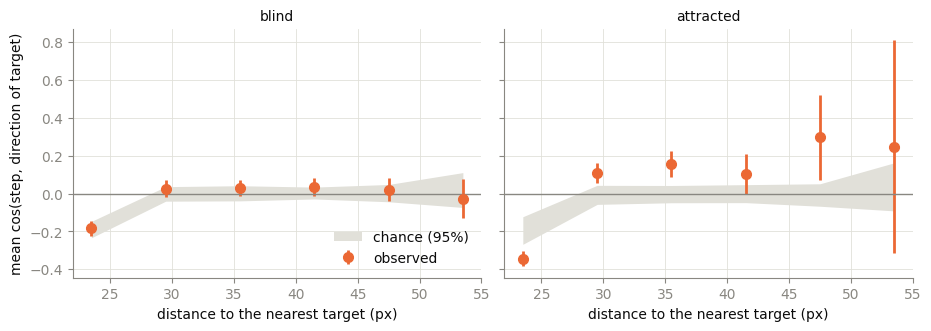

In [ ]:
BINS = CONTACT + np.arange(0, 37, 6)
axes = panels(2, (4.6, 3.2), sharey=True)
for ax, name in zip(axes, ("blind", "attracted")):
    bias = approach_bias(runs[name]["targets"], runs[name]["effectors"], CONTACT, shape=FIELD, bins=BINS,
                         border=80, n_shifts=99)
    ax.fill_between(bias["distance"], bias["null_low"], bias["null_high"], color=GRID, lw=0, label="chance (95%)")
    plot_estimates(ax, bias["distance"], bias["mean_cos"], bias["mean_cos"] - 1.96 * bias["sem"],
                   bias["mean_cos"] + 1.96 * bias["sem"], EFFECTORS, label="observed")
    ax.axhline(0, color=MUTED, lw=1)
    ax.set(xlabel="distance to the nearest target (px)", title=name)
axes[0].set_ylabel("mean cos(step, direction of target)")
axes[0].legend(loc="lower right");

Blind effectors stay within the chance band at every distance. Attracted
effectors head for the targets out to about 50 px. The first bin, just
outside contact, is below the band for both: the steps that start there and
do not end in contact are the ones that turned away. For attracted
effectors, almost every step there ends in contact, so the few left lean
away even more. Read the bins past the first one.

### When does the recruitment start?

In the third experiment, the effectors are blind for the first 50 frames and
attracted after. Over the whole movie, the arrival rate averages the two
phases. With `time_bins`, each time window is tested on its own, against the
shifted tracks over the same window. If the effectors change their motility
during the movie, the shifted tracks change in the same way, so a change in
speed alone does not look like recruitment.

first window above chance starts at frame 50 (true onset: 50)


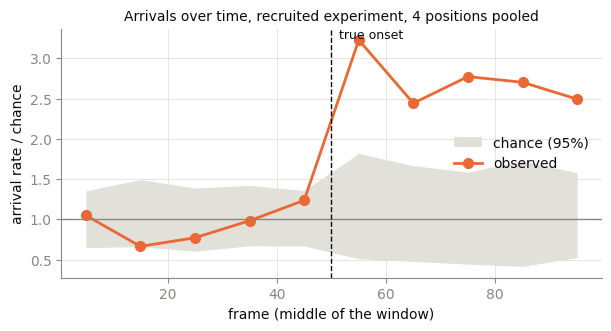

In [ ]:
windows = arrival_test(runs["recruited"]["targets"], runs["recruited"]["effectors"], CONTACT, shape=FIELD,
                       n_shifts=199, time_bins=10)
pooled = windows[windows["position"] == "all"]
mid = (pooled["window_start"] + pooled["window_end"]) / 2

ax = panels(size=(6, 3.2))
ax.fill_between(mid, pooled["null_low"] / pooled["null_rate"], pooled["null_high"] / pooled["null_rate"],
                color=GRID, lw=0, label="chance (95%)")
ax.plot(mid, pooled["ratio"], "o-", color=EFFECTORS, ms=7, lw=2, label="observed")
ax.axhline(1, color=MUTED, lw=1)
mark(ax, ONSET, "true onset")
ax.set(xlabel="frame (middle of the window)", ylabel="arrival rate / chance",
       title="Arrivals over time, recruited experiment, 4 positions pooled")
ax.legend(loc="center right")
first = pooled.loc[pooled["p_value"] < 0.05, "window_start"]
recovered_onset = int(first.iloc[0]) if len(first) else None
print(f"first window above chance starts at frame {recovered_onset} (true onset: {ONSET})")

The arrival rate stays at chance until the onset and rises above it after;
the first window above chance starts at the true onset, to within the
width of a window (10 frames here).

**With real data**, these tests say whether arrivals beat chance for the
motion the effectors actually have. They do not say what draws the
effectors: compare with a control where attraction should be absent
(non-cognate targets, a blocking antibody, beads) and run the same tests,
with the positions as replicates. Also check:

- **Field size**: the shifts wrap around the field, so pass the true image
  size (`shape`).
- **Contact distance**: scan a few distances; a real effect holds at all of
  them once they reach the capture range.
- **Density**: with too few effectors or targets per field, the tests have
  little power. With crowded fields, every step starts near a target, and
  the approach bias has no room to show.
- **Frame rate**: the steps must be short compared with the range of the
  attraction, or the approach bias averages it away.